# TruthLens: AI-Generated vs Real Image Detection

In this notebook I train **two CNN models** on the CIFAKE dataset to classify images as real or AI-generated:

1. **Model 1 (Baseline):** a simple CNN. It works, but it has problems.
2. **Model 2 (Improved):** a deeper CNN with BatchNormalization, built after studying where Model 1 failed.

Both models are compared at the end.

In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from sklearn.metrics import classification_report, confusion_matrix

### Dataset load

In [30]:
IMG_SIZE = (32, 32)   
BATCH_SIZE = 64       

# Training data (90%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "train",
    validation_split=0.1,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Validation data (10%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "train",
    validation_split=0.1,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

# Test data 
test_ds = tf.keras.utils.image_dataset_from_directory(
    "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 100000 files belonging to 2 classes.
Using 90000 files for training.
Found 100000 files belonging to 2 classes.
Using 10000 files for validation.
Found 20000 files belonging to 2 classes.
Classes: ['FAKE', 'REAL']


### Visualize sample images

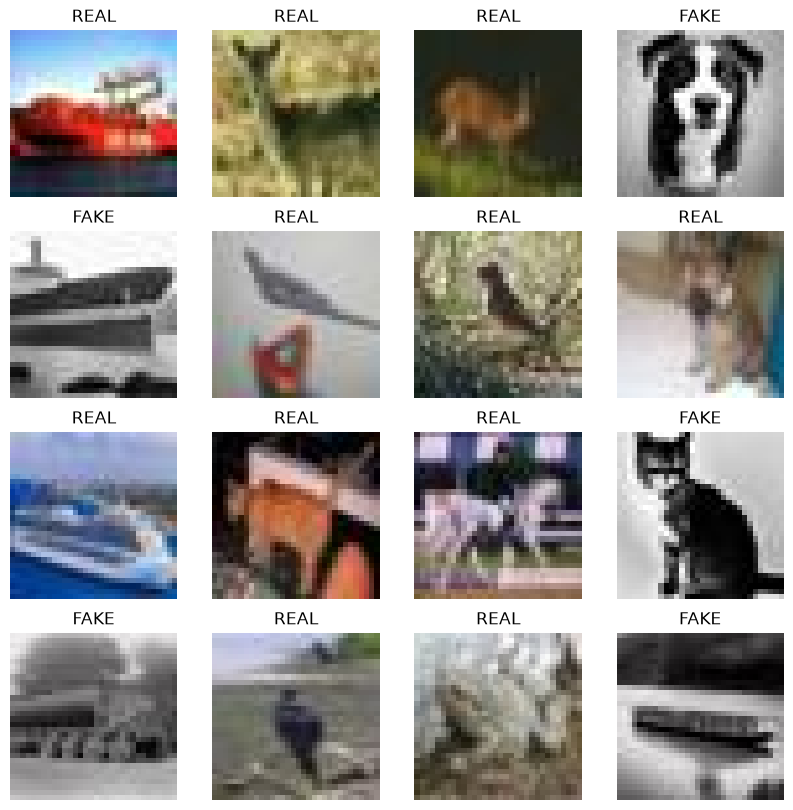

In [31]:
plt.figure(figsize=(10, 10))

# take(1) gives us just one batch (64 images)
for images, labels in train_ds.take(1):
    for i in range(16):
        plt.subplot(4, 4, i + 1)                      
        plt.imshow(images[i].numpy().astype("uint8")) 
        plt.title(class_names[int(labels[i][0])])     
        plt.axis("off")                                

plt.show()

### Speed up data loading (shared by both models)

In [32]:
AUTOTUNE = tf.data.AUTOTUNE

# cache keeps images in memory after the first epoch, prefetch prepares the next batch while the model trains
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

---
# Part 1: Model 1 (Baseline CNN)

A simple CNN with three Conv + Pool blocks. Augmentation here is a random flip and a small random rotation. Normalization (`Rescaling`) and augmentation are built into the model, so the saved file handles preprocessing itself.

### Augmentation for Model 1

Random changes applied only during training. Validation and test data stay untouched for fair evaluation.

In [33]:
# Model 1 augmentation: flip + small rotation
data_augmentation_v1 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),   # randomly mirror the image left-right
    layers.RandomRotation(0.05),       # rotate by a small random angle
])

### Model 1 architecture

Input (32x32x3)

→ Augmentation (flip + rotation, training only)

→ Rescaling (0-255 → 0-1)

→ Conv 32 → MaxPool

→ Conv 64 → MaxPool

→ Conv 128 → MaxPool

→ Flatten

→ Dense 128 → Dropout 0.5

→ Dense 1 (Sigmoid)

In [34]:
model_v1 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),         # 32x32 image, 3 color channels (RGB)

    data_augmentation_v1,                    # only active during training
    layers.Rescaling(1./255),                # normalize pixels to 0-1

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),                     # randomly turns off 50% of neurons during training
    layers.Dense(1, activation="sigmoid")    # output: probability of REAL (FAKE = 0, REAL = 1)
])

model_v1.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159,041 (621.25 KB)

 Trainable params: 159,041 (621.25 KB)

 Non-trainable params: 0 (0.00 B)

### Compile Model 1

In [35]:
model_v1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

### Train Model 1 (EarlyStopping and ModelCheckpoint)

In [36]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop if validation loss does not improve for 3 epochs in a row
early_stop_v1 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True   # go back to the best epoch's weights
)

# Save the model every time validation loss reaches a new best
checkpoint_v1 = ModelCheckpoint(
    "truthlens_model.keras",
    monitor="val_loss",
    save_best_only=True
)

In [39]:
history_v1 = model_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_v1, checkpoint_v1]
)

Epoch 1/20


c:\Users\ujjwa\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 54s 26ms/step - accuracy: 0.8082 - loss: 0.4133 - val_accuracy: 0.7444 - val_loss: 0.6358
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.8742 - loss: 0.2997 - val_accuracy: 0.8388 - val_loss: 0.3680
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.8953 - loss: 0.2580 - val_accuracy: 0.8577 - val_loss: 0.3428
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.9046 - loss: 0.2349 - val_accuracy: 0.8611 - val_loss: 0.3370
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.9119 - loss: 0.2211 - val_accuracy: 0.8645 - val_loss: 0.3231
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.9168 - loss: 0.2070 - val_accuracy: 0.8344 - val_loss: 0.4183
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.9208 - loss: 0.1984 - val_accuracy: 0.8368 - val_loss: 0.4627
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.9254 - loss: 0.18

### Model 1: best epoch and training curves

In [40]:
# Which epoch had the lowest validation loss? (counting starts at 1)
best_epoch_v1 = np.argmin(history_v1.history["val_loss"]) + 1
print("Best epoch:", best_epoch_v1)
print("Best val_loss:", min(history_v1.history["val_loss"]))
print("Val accuracy at that epoch:", history_v1.history["val_accuracy"][best_epoch_v1 - 1])

Best epoch: 5
Best val_loss: 0.32314229011535645
Val accuracy at that epoch: 0.8644999861717224


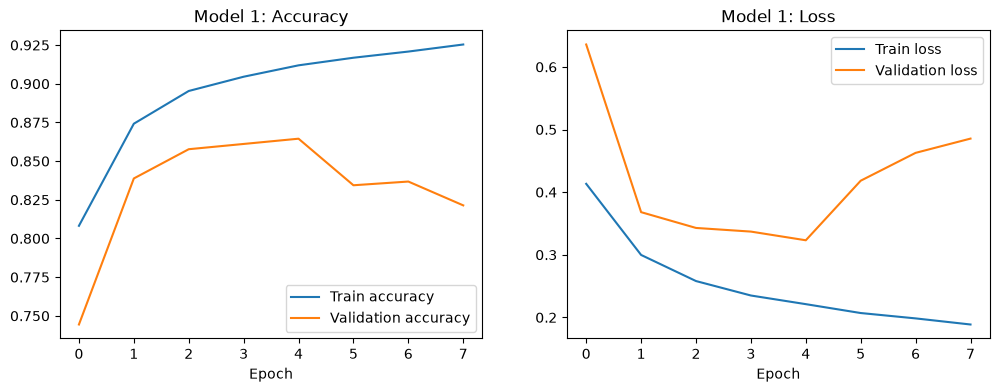

In [41]:
acc_v1 = history_v1.history["accuracy"]
val_acc_v1 = history_v1.history["val_accuracy"]
loss_v1 = history_v1.history["loss"]
val_loss_v1 = history_v1.history["val_loss"]

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(acc_v1, label="Train accuracy")
plt.plot(val_acc_v1, label="Validation accuracy")
plt.title("Model 1: Accuracy")
plt.xlabel("Epoch")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(loss_v1, label="Train loss")
plt.plot(val_loss_v1, label="Validation loss")
plt.title("Model 1: Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

### Model 1: evaluation on the test set

In [42]:
# 1. Overall test accuracy
test_loss_v1, test_acc_v1 = model_v1.evaluate(test_ds)
print("Model 1 test accuracy:", test_acc_v1)

# 2. Predicted probabilities (between 0 and 1)
y_prob_v1 = model_v1.predict(test_ds)

# 3. Convert probabilities to 0/1 labels (above 0.5 means REAL)
y_pred_v1 = (y_prob_v1 > 0.5).astype(int).ravel()

# 4. True labels from the test set (test_ds is not shuffled, so the order matches)
y_true = np.concatenate([labels.numpy() for images, labels in test_ds]).astype(int).ravel()

# 5. Precision, recall, f1-score for each class
print(classification_report(y_true, y_pred_v1, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.8602 - loss: 0.3305
Model 1 test accuracy: 0.8601999878883362
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

        FAKE       0.79      0.98      0.88     10000
        REAL       0.98      0.74      0.84     10000

    accuracy                           0.86     20000
   macro avg       0.88      0.86      0.86     20000
weighted avg       0.88      0.86      0.86     20000



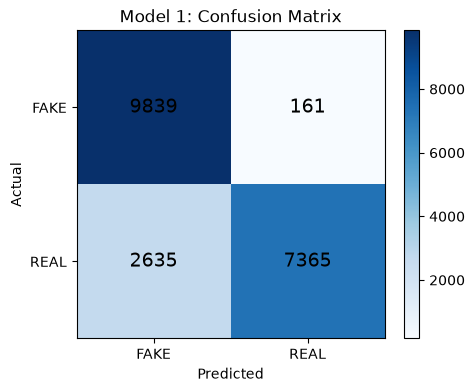

In [43]:
cm_v1 = confusion_matrix(y_true, y_pred_v1)

plt.figure(figsize=(5, 4))
plt.imshow(cm_v1, cmap="Blues")
plt.title("Model 1: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)  

# write the number inside each box
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_v1[i, j], ha="center", va="center", fontsize=14)

plt.colorbar()
plt.show()

### Model 1: results (recorded from my original run)

| Metric | Value |
|---|---|
| Training stopped at | epoch 7 of 20 (EarlyStopping) |
| Best epoch (lowest val loss) | epoch 5 |
| Best val loss / val accuracy | 0.3231 / 86.45% |
| **Test accuracy** | **86.01%** |

| Class | Precision | Recall | F1-score |
|---|---|---|---|
| FAKE | 0.79 | 0.98 | 0.88 |
| REAL | 0.98 | 0.74 | 0.84 |

| | Predicted FAKE | Predicted REAL |
|---|---|---|
| **Actual FAKE** | 9839 | 161 |
| **Actual REAL** | 2635 | 7365 |

*These numbers come from my first run. Re-running Model 1 may give slightly different values because of random initialization.*

---
## Why train a second model?

Model 1 reached 86.4% test accuracy, but the accuracy number hides three problems:

1. **It overfits very quickly.** The best epoch was only epoch 2. After that, training accuracy kept rising (91.2% at epoch 5) while validation accuracy stayed behind (84.8%).
2. **It is biased towards FAKE.** The confusion matrix shows that 2441 real images (24%) were wrongly labelled as FAKE, while only 273 fake images were missed. REAL recall is just 0.76 and FAKE precision is 0.80. Calling a real photo "AI-generated" is a bad mistake for a detector.
3. **The architecture is basic.** Every convolution goes straight into pooling, with no normalization between layers, so training is less stable.

**My hypotheses and the changes for Model 2:**

| Change | Reason |
|---|---|
| Add **BatchNormalization** after every Conv layer | More stable and smoother training |
| Use **two Conv layers per block** (`padding="same"`) | Learn richer texture patterns before pooling |
| Add **Dropout (0.25) after each block** | Reduce overfitting |
| **Remove random rotation**, keep only flip | Rotation interpolates pixels and may blur the very fine textures that separate real from fake in 32x32 images |
| Add **ReduceLROnPlateau** and increase EarlyStopping patience to 5 | Let the model keep improving with smaller steps once progress slows |

*Note: I changed several things at once, so this experiment cannot tell which single change helped the most.*

---
# Part 2: Model 2 (Improved CNN)

### Preprocessing for Model 2

Data augmentation: We randomly flip training images each epoch to prevent memorization and reduce overfitting, while keeping validation and test data untouched for fair evaluation. Random rotation was removed in this version.

In [44]:
# Random changes applied only during training
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),   # randomly mirror the image left-right
])

### Model 2 architecture

Input (32x32x3)

→ Augmentation (flip only, training only)

→ Rescaling (0-255 → 0-1)

→ Block 1: [Conv 32 → BatchNorm → ReLU] x2 → MaxPool → Dropout 0.25

→ Block 2: [Conv 64 → BatchNorm → ReLU] x2 → MaxPool → Dropout 0.25

→ Block 3: [Conv 128 → BatchNorm → ReLU] x2 → MaxPool → Dropout 0.25

→ Flatten

→ Dense 128 → Dropout 0.5

→ Dense 1 (Sigmoid)

## Model building

In [45]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_6 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 551,201 (2.10 MB)

 Trainable params: 550,305 (2.10 MB)

 Non-trainable params: 896 (3.50 KB)

### Compile the model

In [46]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## Training the Model

EarlyStopping and ModelCheckpoint

In [47]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# patience 5, give the model more chances to improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# new file name so the baseline model is not overwritten
checkpoint = ModelCheckpoint(
    "truthlens_model_v2.keras",
    monitor="val_loss",
    save_best_only=True
)

# if val_loss is stuck for 2 epochs, halve the learning rate
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2
)

### Train

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,                                  
    callbacks=[early_stop, checkpoint, reduce_lr] 
)

Epoch 1/30


c:\Users\ujjwa\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 197s 137ms/step - accuracy: 0.8880 - loss: 0.2839 - val_accuracy: 0.8979 - val_loss: 0.2775 - learning_rate: 0.0010
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 201s 143ms/step - accuracy: 0.9256 - loss: 0.1998 - val_accuracy: 0.9309 - val_loss: 0.1803 - learning_rate: 0.0010
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 197s 140ms/step - accuracy: 0.9349 - loss: 0.1739 - val_accuracy: 0.9417 - val_loss: 0.1585 - learning_rate: 0.0010
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 201s 143ms/step - accuracy: 0.9407 - loss: 0.1598 - val_accuracy: 0.9434 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 199s 142ms/step - accuracy: 0.9447 - loss: 0.1481 - val_accuracy: 0.9439 - val_loss: 0.1451 - learning_rate: 0.0010
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 204s 145ms/step - accuracy: 0.9482 - loss: 0.1392 - val_accuracy: 0.9277 - val_loss: 0.1961 - learning_rate: 0.0010
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 198s 141ms/step - acc

In [24]:
# Which epoch had the lowest validation loss? (counting starts at 1)
best_epoch = np.argmin(history.history["val_loss"]) + 1
print("Best epoch:", best_epoch)
print("Best val_loss:", min(history.history["val_loss"]))
print("Val accuracy at that epoch:", history.history["val_accuracy"][best_epoch - 1])

Best epoch: 22
Best val_loss: 0.07215443253517151
Val accuracy at that epoch: 0.9763000011444092


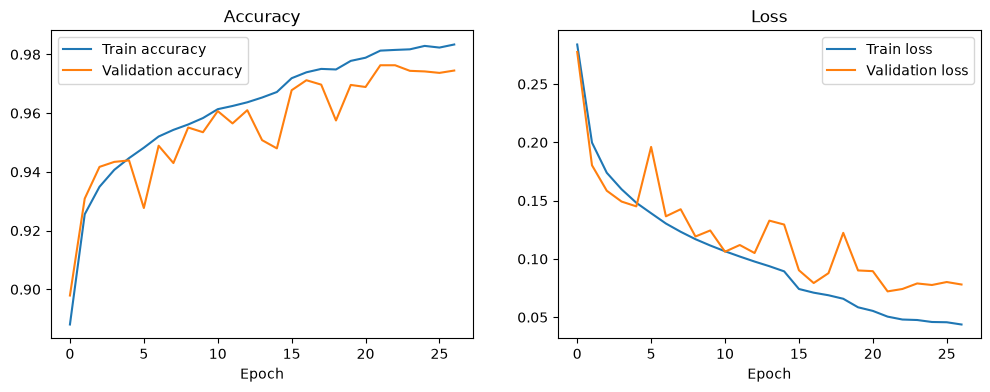

In [25]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(acc, label="Train accuracy")
plt.plot(val_acc, label="Validation accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(loss, label="Train loss")
plt.plot(val_loss, label="Validation loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [26]:
# 1. Overall test accuracy
test_loss, test_acc = model.evaluate(test_ds)
print("Test accuracy:", test_acc)

# 2. Get predictions (probabilities between 0 and 1)
y_prob = model.predict(test_ds)

# 3. Convert probabilities to 0/1 labels (above 0.5 means REAL)
y_pred = (y_prob > 0.5).astype(int).ravel()

# 4. Collect the true labels from the test set
y_true = np.concatenate([labels.numpy() for images, labels in test_ds]).astype(int).ravel()

# 5. Precision, recall, f1-score for each class
print(classification_report(y_true, y_pred, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9727 - loss: 0.0793
Test accuracy: 0.9726999998092651
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step
              precision    recall  f1-score   support

        FAKE       0.97      0.97      0.97     10000
        REAL       0.97      0.97      0.97     10000

    accuracy                           0.97     20000
   macro avg       0.97      0.97      0.97     20000
weighted avg       0.97      0.97      0.97     20000



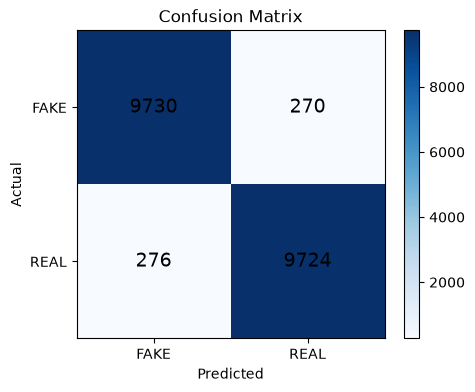

In [27]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

# write the number inside each box
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)

plt.colorbar()
plt.show()

## Conclusion

- **Model 2 is clearly better.** Test accuracy rose from 86% to **97.3%**, and validation accuracy (97.6%) is close to test accuracy, so the model generalizes well on this dataset.
- **The bias is gone.** Model 1 wrongly flagged 2441 real images as fake. Model 2 makes almost equal errors on both classes (276 vs 270).
- **Training became stable.** Model 1 peaked at epoch 2, while Model 2 kept improving until epoch 22, helped by BatchNormalization and the learning-rate schedule.
- **Cause of the improvement is not isolated.** Several changes were made together, so I cannot say which one contributed most. Ablation experiments would be needed to find out.

### Limitations

The 97.3% score is on the **CIFAKE test set only**. When I tested the model on high-resolution real photos taken with a camera, it often labelled them as **AI-generated**. CIFAKE's real images come from CIFAR-10 (small, low-resolution, only 10 object categories) and all fake images come from one generator (Stable Diffusion). The model likely learned the style of this dataset rather than general properties of real photographs.

### Next steps

- Train on a higher-resolution, more diverse dataset that contains real camera photos and images from several generators.
- Use **transfer learning** (for example EfficientNetB0) and test on generators not seen during training.
- Add Grad-CAM heatmaps to see what the model looks at.

The trained models are saved as `truthlens_model.keras` (Model 1) and `truthlens_model_v2.keras` (Model 2, used in the Streamlit app).